In [35]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

In [36]:
Mart_data = pd.read_csv('../datasets/bigmart.csv')

In [37]:
Mart_data.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


## Data Preprocessing

In [38]:
Mart_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [39]:
Mart_data.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


### Handling Missing Values

In [40]:
Mart_data.isnull().sum()

Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

In [41]:
Mart_data['Outlet_Size'].unique()

array(['Medium', nan, 'High', 'Small'], dtype=object)

In [42]:
Mart_data['Outlet_Size'].value_counts()

Outlet_Size
Medium    2793
Small     2388
High       932
Name: count, dtype: int64

In [43]:
Mart_data['Outlet_Size'].mode()[0]

'Medium'

In [44]:
Mart_data['Outlet_Size']=Mart_data['Outlet_Size'].fillna(Mart_data['Outlet_Size'].mode()[0])

In [45]:
Mart_data['Item_Weight']=Mart_data['Item_Weight'].fillna(Mart_data['Item_Weight'].mean())

In [46]:
Mart_data.isnull().sum()

Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
dtype: int64

In [47]:
Mart_data.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,Medium,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [48]:
Mart_data.dtypes

Item_Identifier               object
Item_Weight                  float64
Item_Fat_Content              object
Item_Visibility              float64
Item_Type                     object
Item_MRP                     float64
Outlet_Identifier             object
Outlet_Establishment_Year      int64
Outlet_Size                   object
Outlet_Location_Type          object
Outlet_Type                   object
Item_Outlet_Sales            float64
dtype: object

## Data visulization

c:\Users\PMYLS\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


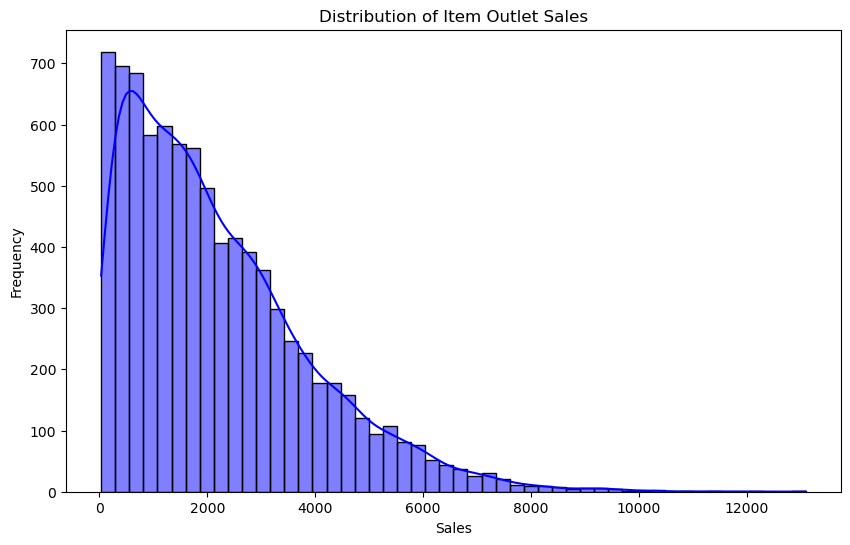

In [49]:
plt.figure(figsize=(10, 6))
sns.histplot(Mart_data['Item_Outlet_Sales'], bins=50, kde=True, color='blue')
plt.title('Distribution of Item Outlet Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()


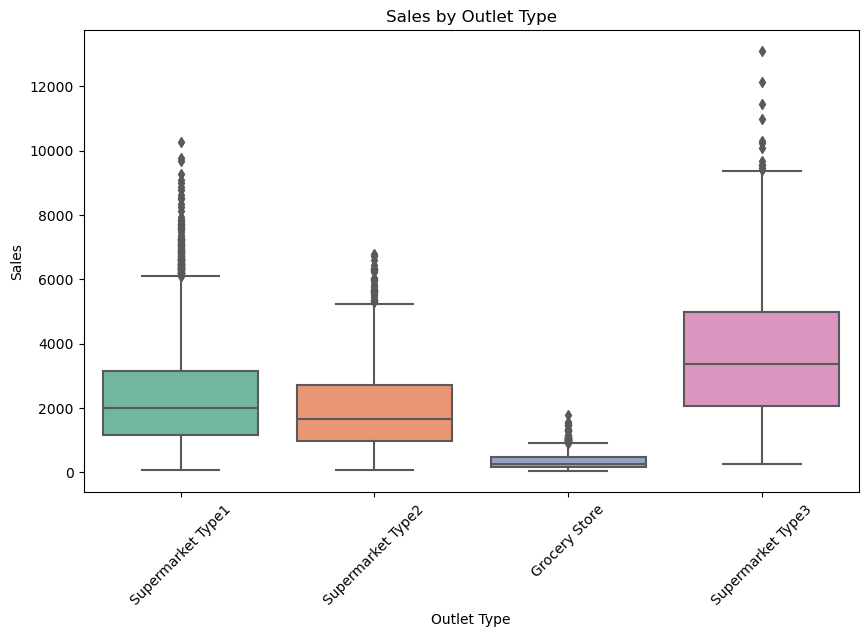

In [50]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=Mart_data, x='Outlet_Type', y='Item_Outlet_Sales', palette='Set2')
plt.title('Sales by Outlet Type')
plt.xlabel('Outlet Type')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.show()


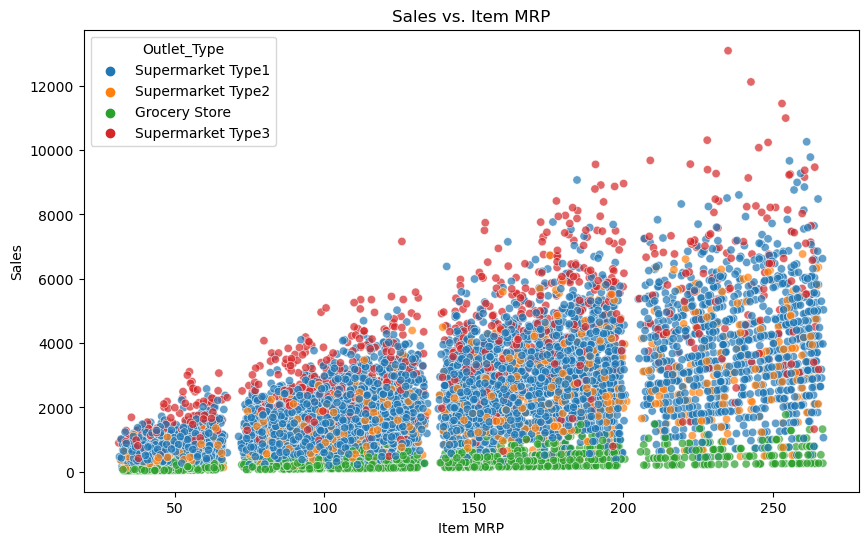

In [51]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=Mart_data, x='Item_MRP', y='Item_Outlet_Sales', alpha=0.7, hue='Outlet_Type')
plt.title('Sales vs. Item MRP')
plt.xlabel('Item MRP')
plt.ylabel('Sales')
plt.show()



C:\Users\PMYLS\AppData\Local\Temp\ipykernel_12376\3863312988.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=Mart_data, x='Outlet_Establishment_Year', y='Item_Outlet_Sales', palette='pastel', ci=None)


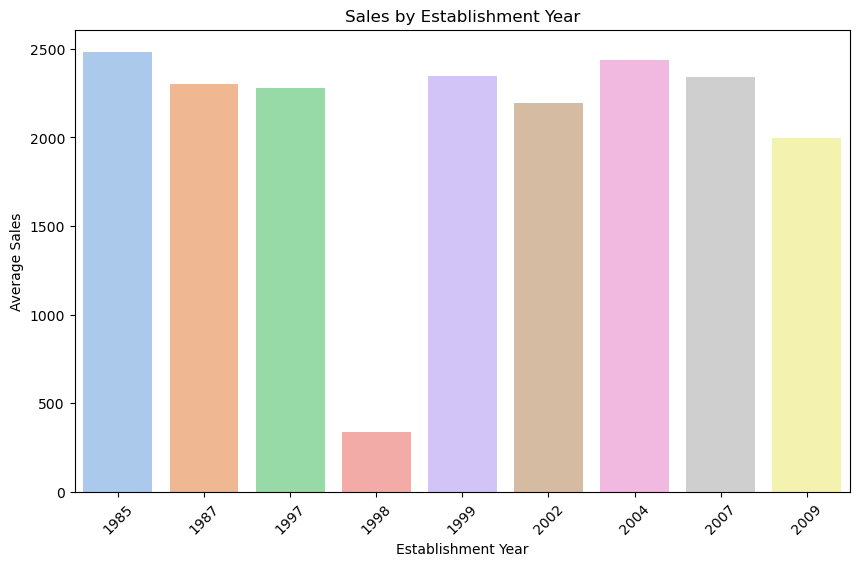

In [52]:
plt.figure(figsize=(10, 6))
sns.barplot(data=Mart_data, x='Outlet_Establishment_Year', y='Item_Outlet_Sales', palette='pastel', ci=None)
plt.title('Sales by Establishment Year')
plt.xlabel('Establishment Year')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)
plt.show()


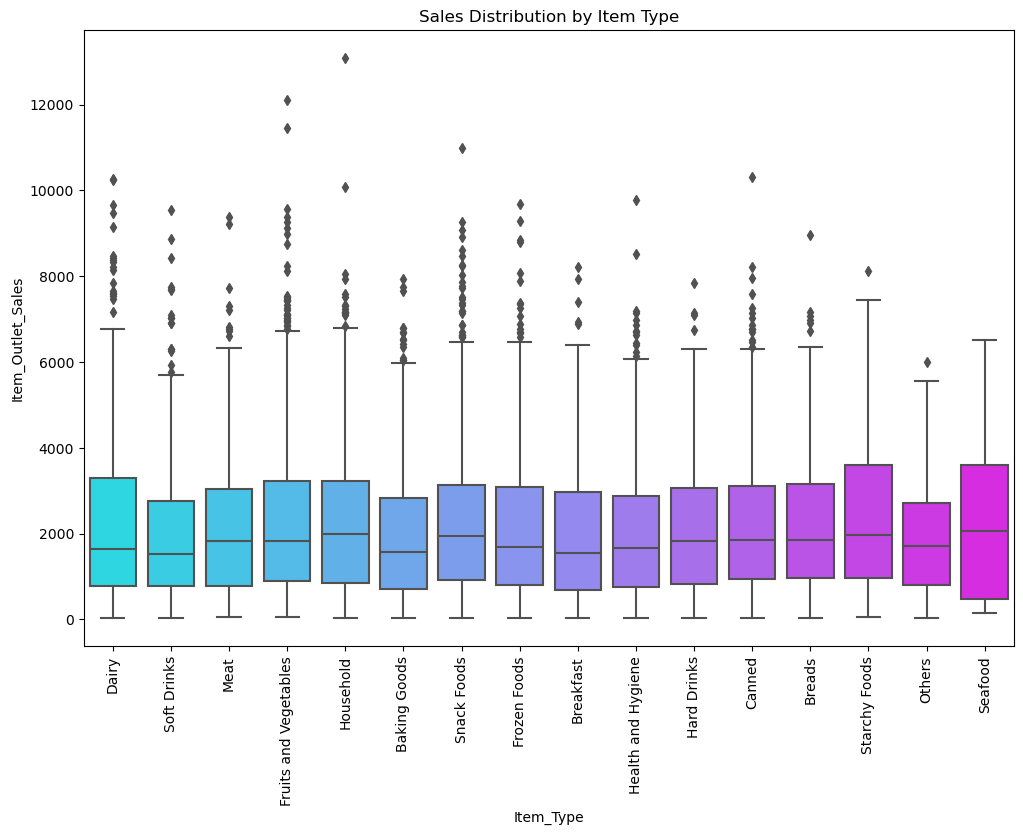

In [53]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=Mart_data, x='Item_Type', y='Item_Outlet_Sales', palette='cool')
plt.title('Sales Distribution by Item Type')
plt.xticks(rotation=90)
plt.show()


## Encoding Catagorical Columns

In [54]:
Mart_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                8523 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                8523 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [55]:
Mart_data.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,Medium,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [56]:
Mart_data['Item_Fat_Content'].value_counts()

Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

In [57]:
Mart_data=Mart_data.replace({'Item_Fat_Content': {'low fat':'Low Fat','LF':'Low Fat', 'reg':'Regular'}})

In [58]:
Mart_data['Item_Fat_Content'].value_counts()

Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

In [59]:
Mart_data['Outlet_Location_Type'].unique()

array(['Tier 1', 'Tier 3', 'Tier 2'], dtype=object)

In [60]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder


# ---- 1. Label Encoding ----
label_encoder = LabelEncoder()
Mart_data['Outlet_Size'] = label_encoder.fit_transform(Mart_data['Outlet_Size'])
    



In [61]:
one_hot_encode_cols = ['Outlet_Location_Type', 'Outlet_Type', 'Item_Type','Item_Fat_Content']
# ---- 2. One-Hot Encoding ----
ohe = OneHotEncoder(sparse=False, drop='first')  # drop='first' avoids dummy variable trap

# Apply One-Hot Encoding and convert result to DataFrame
ohe_encoded = ohe.fit_transform(Mart_data[one_hot_encode_cols])
ohe_df = pd.DataFrame(ohe_encoded, columns=ohe.get_feature_names_out(one_hot_encode_cols))

# Drop original columns and concatenate the new one-hot encoded columns
Mart_df = pd.concat([Mart_data.drop(columns=one_hot_encode_cols), ohe_df], axis=1)

print("One-hot encoded columns:")
print(ohe_df.head())

One-hot encoded columns:
   Outlet_Location_Type_Tier 2  Outlet_Location_Type_Tier 3  \
0                          0.0                          0.0   
1                          0.0                          1.0   
2                          0.0                          0.0   
3                          0.0                          1.0   
4                          0.0                          1.0   

   Outlet_Type_Supermarket Type1  Outlet_Type_Supermarket Type2  \
0                            1.0                            0.0   
1                            0.0                            1.0   
2                            1.0                            0.0   
3                            0.0                            0.0   
4                            1.0                            0.0   

   Outlet_Type_Supermarket Type3  Item_Type_Breads  Item_Type_Breakfast  \
0                            0.0               0.0                  0.0   
1                            0.0           

c:\Users\PMYLS\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


In [62]:
Mart_df.head()

,Item_Identifier,Item_Weight,Item_Visibility,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Item_Outlet_Sales,Outlet_Location_Type_Tier 2,Outlet_Location_Type_Tier 3,...,Item_Type_Hard Drinks,Item_Type_Health and Hygiene,Item_Type_Household,Item_Type_Meat,Item_Type_Others,Item_Type_Seafood,Item_Type_Snack Foods,Item_Type_Soft Drinks,Item_Type_Starchy Foods,Item_Fat_Content_Regular
0,FDA15,9.30,0.016047,249.8092,OUT049,1999,1,3735.1380,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,DRC01,5.92,0.019278,48.2692,OUT018,2009,1,443.4228,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2,FDN15,17.50,0.016760,141.6180,OUT049,1999,1,2097.2700,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,FDX07,19.20,0.000000,182.0950,OUT010,1998,1,732.3800,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,NCD19,8.93,0.000000,53.8614,OUT013,1987,0,994.7052,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [63]:
Y= Mart_data['Item_Outlet_Sales']
X= Mart_df.drop(columns=['Item_Identifier','Outlet_Identifier','Item_Outlet_Sales'])

In [64]:
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.20,random_state=2)

In [65]:
model = RandomForestRegressor()
model.fit(X_train,Y_train)

RandomForestRegressor()

In [68]:
yhat = model.predict(X_test)
mse = mean_squared_error(Y_test, yhat)
mae = mean_absolute_error(Y_test, yhat)
r2 = r2_score(Y_test, yhat)

# Print the results
print(f"Mean Squared Error (MSE): {mse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R-squared (R2): {r2}")

Mean Squared Error (MSE): 1409961.3504608083
Mean Absolute Error (MAE): 831.9077709900293
R-squared (R2): 0.5432694435022488


In [69]:

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

In [70]:
from sklearn.model_selection import RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=50,  # Number of combinations to try
    cv=3,  # Cross-validation folds
    verbose=2,
    random_state=42,
    n_jobs=-1
)

In [71]:
# Fit to training data
random_search.fit(X_train, Y_train)

# Step 5: Evaluate the best model
best_rf = random_search.best_estimator_

Fitting 3 folds for each of 50 candidates, totalling 150 fits


In [73]:
y_pred = best_rf.predict(X_test)
r2_scor = r2_score(y_pred,Y_test)
# Calculate RMSE
rmse = np.sqrt(mean_squared_error(Y_test, y_pred))
print(f"Best Parameters: {random_search.best_params_}")
print(f"Test RMSE: {rmse}")
print(f"R-squared (R2): {r2}")

Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 10, 'bootstrap': True}
Test RMSE: 1149.214541651689
R-squared (R2): 0.5432694435022488
